# 0. Introducción

En este ejercicio de datos se estudia la **distribución de las instalaciones deportivas** en la provincia de Sevilla respecto al nivel de renta depara cada código postal.

Para ello, contamos con los datos abiertos proporcionados por el **Instituto Nacional de Estadística (INE)** sobre **nivel de renta media por persona y sección censal**, así como los datos de la Junta de Andalucía sobre la localización de instalaciones deportivas por código postal, junto con el tipo de instalación deportiva y el deporte que se practica en ellas.

De esta forma, en este notebook haremos un recorrido por el análisis necesario para estudiar la relación entre la distribución de las instalaciones deportivas y nivel de renta estimado, cubriendo diferentes aspectos del análisis de datos tales como:

- Lectura de ficheros .txt y .csv
- Estructuración de los datos en DataFrames de Pandas
- Filtrado de datos para  seleccionar periodos de tiempo, propiedades  o áreas concretas
- Conversión de formatos y generación de archivos de salida en formato .geojson
- Combinación de diferentes Dataframes para la obtención de nuevas métricas  
- Creación de histogramas

# 1. Proceso de desarrollo

A lo largo del proceso de desarrollo veremos las diferentes etapas de análisis, que van desde la lectura de los ficheros a la obtención de resultados numéricos,  así como la creación de gráficas y mapas a partir de resultados parciales.

# 1.1 Librerías

El primer paso de este ejercicio es la importación dentro del entorno Python del notebook de una serie de librerías . En concreto trabajaremos con Pandas para estructurar los datos, Numpy para realizar cálculos básicos, Scipy para calcular interpolaciones, GeoPandas para trabajar con los datos geográficos de las secciones censales y los códigos postales y, por último, Matplotlib para crear gráficos básicos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import scipy.stats as stats
import seaborn as sns
from scipy.interpolate import interp1d
import geopandas as gpd
import io
from google.colab import files
import warnings
warnings.filterwarnings("ignore")

## 1.2 Lectura de secciones censales.

Una vez importadas las librerías procedemos a la lectura de los tramos de vía que componen las secciones censales y a los códigos postales, y que obtenemos del INE a través de un fichero .txt.

Si realizamos el ejercicio en nuestro propio entorno de programación podemos leer el fichero de entrada a través de la función `.read_csv()` de la librería Pandas:

`content = pd.read_fwf('.\TRAM-NAL-SEVILLA.txt')`

Por el contrario, si optamos por hacer el ejercicio en este notebook, una vez descargado, utilizamos la función `.upload()` de Google Colab para seleccionar el fichero .txt con los datos de tramos de vía, tal y como se muestra a continuación:


In [2]:
uploaded = files.upload()

Saving TRAM-NAL-SEVILLA.txt to TRAM-NAL-SEVILLA.txt


Una vez hemos incorporado el fichero de texto al notebook, establecemos la estructura de columnas del fichero de entrada en base a la información que ofrece el INE con el fin deextraer durante la lectura los datos de provincia, municipio, distrito, sección y código postal.

In [3]:
column_specs = [
       (0, 2),    # CPRO (Provincia)
       (2, 5),    # CMUN (Municipio)
       (5, 7),    # DISTR (Distrito)
       (7, 10),   # SECC (Sección)
       (42, 47),  # CPOS (Código Postal)
       ]
column_names = ['CPRO', 'CMUN', 'DISTR', 'SECC', 'CPOS']

Definidos los campos, procedemos a la lectura del finchero como un DataFrame de Pandas, estructurando los datos de forma matricial en filas y columnas.

In [4]:
df_tramos = pd.read_fwf('TRAM-NAL-SEVILLA.txt', colspecs=column_specs, names=column_names, dtype=str)
df_tramos

,CPRO,CMUN,DISTR,SECC,CPOS
0,41,001,01,001,41550
1,41,001,01,001,41550
2,41,001,01,001,41550
3,41,001,01,001,41550
4,41,001,02,001,41550
...,...,...,...,...,...
53711,41,904,01,001,41719
53712,41,904,01,001,41719
53713,41,904,01,001,41719
53714,41,904,01,001,41719


A partir de la información contenida en el DataFrame es posible crear el código de cada sección censal concatenando los diferentes campos en el orden determinado:

In [5]:
df_tramos['SSCC'] = df_tramos['CPRO'] + df_tramos['CMUN'] + df_tramos['DISTR'] + df_tramos['SECC']

## 1.3 Cálculo de la matriz de pesos

Una vez creados los códigos para cada sección censal, calculamos el peso que tiene cada sección dentro de un código postal. Como hemos visto en la parte descriptiva del ejercicio, hay secciones que están íntegramente en el área definida por un código postal, pero también hay otras secciones que se distribuyen por varios códigos postales. Lo primero que hacemos es contar cuántas veces aparece la combinación única sección censal - código postal.

In [6]:
matriz_pesos = df_tramos.groupby(['SSCC', 'CPOS']).size().reset_index(name='conteo_tramos')

A continuación calculamos el número total de tramos de vía que tiene cada sección censal.

In [7]:
matriz_pesos['total_tramos_sscc'] = matriz_pesos.groupby('SSCC')['conteo_tramos'].transform('sum')

Seguidamente, definimos el peso de cada sección como la proporción de tramos en un código respecto al total de tramos de esa sección.Además definimos una nueva variable que indica si una sección está íntegramente en un código o si por el contrario sólo una fracción de ella está contenida en un código.

In [8]:
matriz_pesos['peso_asignacion'] = matriz_pesos['conteo_tramos'] / matriz_pesos['total_tramos_sscc']
matriz_pesos['completo'] = matriz_pesos['peso_asignacion'].apply(lambda x: 'completo' if x == 1 else 'parcial')
matriz_pesos

,SSCC,CPOS,conteo_tramos,total_tramos_sscc,peso_asignacion,completo
0,4100101001,41550,46,46,1.0,completo
1,4100102001,41550,62,62,1.0,completo
2,4100201001,41380,93,93,1.0,completo
3,4100201002,41380,51,51,1.0,completo
4,4100301001,41809,83,83,1.0,completo
...,...,...,...,...,...,...
1590,4190301003,41749,92,92,1.0,completo
1591,4190301004,41749,33,33,1.0,completo
1592,4190301005,41749,74,74,1.0,completo
1593,4190301006,41749,50,50,1.0,completo


Para poder realizar un mapa del peso de cada sección censal  es necesario asociar cada sección el polígono que define su geometria. Para ello, incorporamos al notebook un fichero .SHP con la geometría de cada sección.

In [9]:
uploaded = files.upload()

Saving SECC_CE_20230101.CPG to SECC_CE_20230101.CPG
Saving SECC_CE_20230101.dbf to SECC_CE_20230101.dbf
Saving SECC_CE_20230101.prj to SECC_CE_20230101.prj
Saving SECC_CE_20230101.sbn to SECC_CE_20230101.sbn
Saving SECC_CE_20230101.sbx to SECC_CE_20230101.sbx
Saving SECC_CE_20230101.shp to SECC_CE_20230101.shp
Saving SECC_CE_20230101.shx to SECC_CE_20230101.shx


A continuación, asignamos un sistema de coordenadas standard, filtramos aquellas secciones que pertenecen a la provincial de Sevilla, identificadascon el Código "41", y renombramos la columna de las secciones por un nombre más intuitivo.

In [10]:
gdf = gpd.read_file('SECC_CE_20230101.shp')
gdf = gdf.to_crs(4326)
gdf['CPRO']=gdf['CPRO'].astype("int64")
gdf = gdf[gdf['CPRO']==41]
gdf.rename(columns={'CUSEC': 'SSCC'}, inplace=True)
gdf

,SSCC,CUMUN,CSEC,CDIS,CMUN,CPRO,CCA,CUDIS,CLAU2,NPRO,NCA,CNUT0,CNUT1,CNUT2,CNUT3,NMUN,geometry
27935,4100101001,41001,001,01,001,41,01,4100101,41001,Sevilla,Andalucía,ES,6,1,8,Aguadulce,"POLYGON ((-5.00606 37.24802, -5.0061 37.24839,..."
27936,4100102001,41001,001,02,001,41,01,4100102,41001,Sevilla,Andalucía,ES,6,1,8,Aguadulce,"POLYGON ((-4.98964 37.22955, -4.9901 37.23004,..."
27937,4100201001,41002,001,01,002,41,01,4100201,41002,Sevilla,Andalucía,ES,6,1,8,Alanís,"POLYGON ((-5.58479 38.13171, -5.5833 38.13014,..."
27938,4100201002,41002,002,01,002,41,01,4100201,41002,Sevilla,Andalucía,ES,6,1,8,Alanís,"POLYGON ((-5.71683 38.04165, -5.71464 38.04118..."
27939,4100301001,41003,001,01,003,41,01,4100301,41003,Sevilla,Andalucía,ES,6,1,8,Albaida del Aljarafe,"POLYGON ((-6.16169 37.42616, -6.16192 37.42599..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35953,4102102004,41021,004,02,021,41,01,4102102,41021,Sevilla,Andalucía,ES,6,1,8,Camas,"POLYGON ((-6.03462 37.39808, -6.03341 37.39388..."
35954,4102102009,41021,009,02,021,41,01,4102102,41021,Sevilla,Andalucía,ES,6,1,8,Camas,"POLYGON ((-6.03293 37.3915, -6.03326 37.393, -..."
35955,4109102002,41091,002,02,091,41,01,4109102,41091,Sevilla,Andalucía,ES,6,1,8,Sevilla,"POLYGON ((-5.98027 37.41001, -5.97979 37.40884..."
35956,4109106010,41091,010,06,091,41,01,4109106,41091,Sevilla,Andalucía,ES,6,1,8,Sevilla,"POLYGON ((-6.00753 37.37903, -6.00787 37.37885..."


Para evitar que una misma sección aparezca varias veces, creamos una tabla con una única fila por sección censal. La sección se clasifica como completa si todos sus tramos están asociados a un único código postal y como parcial si están asociados a más de uno:


In [12]:
output = gdf.merge(matriz_pesos, on='SSCC', how='left')
output

,SSCC,CUMUN,CSEC,CDIS,CMUN,CPRO,CCA,CUDIS,CLAU2,NPRO,...,CNUT1,CNUT2,CNUT3,NMUN,geometry,CPOS,conteo_tramos,total_tramos_sscc,peso_asignacion,completo
0,4100101001,41001,001,01,001,41,01,4100101,41001,Sevilla,...,6,1,8,Aguadulce,"POLYGON ((-5.00606 37.24802, -5.0061 37.24839,...",41550,46,46,1.0,completo
1,4100102001,41001,001,02,001,41,01,4100102,41001,Sevilla,...,6,1,8,Aguadulce,"POLYGON ((-4.98964 37.22955, -4.9901 37.23004,...",41550,62,62,1.0,completo
2,4100201001,41002,001,01,002,41,01,4100201,41002,Sevilla,...,6,1,8,Alanís,"POLYGON ((-5.58479 38.13171, -5.5833 38.13014,...",41380,93,93,1.0,completo
3,4100201002,41002,002,01,002,41,01,4100201,41002,Sevilla,...,6,1,8,Alanís,"POLYGON ((-5.71683 38.04165, -5.71464 38.04118...",41380,51,51,1.0,completo
4,4100301001,41003,001,01,003,41,01,4100301,41003,Sevilla,...,6,1,8,Albaida del Aljarafe,"POLYGON ((-6.16169 37.42616, -6.16192 37.42599...",41809,83,83,1.0,completo
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1568,4102102004,41021,004,02,021,41,01,4102102,41021,Sevilla,...,6,1,8,Camas,"POLYGON ((-6.03462 37.39808, -6.03341 37.39388...",41900,51,51,1.0,completo
1569,4102102009,41021,009,02,021,41,01,4102102,41021,Sevilla,...,6,1,8,Camas,"POLYGON ((-6.03293 37.3915, -6.03326 37.393, -...",41900,12,12,1.0,completo
1570,4109102002,41091,002,02,091,41,01,4109102,41091,Sevilla,...,6,1,8,Sevilla,"POLYGON ((-5.98027 37.41001, -5.97979 37.40884...",41009,7,7,1.0,completo
1571,4109106010,41091,010,06,091,41,01,4109106,41091,Sevilla,...,6,1,8,Sevilla,"POLYGON ((-6.00753 37.37903, -6.00787 37.37885...",41010,16,16,1.0,completo


Una vez hemos asociado a cada geometría su peso correspondiente podemos guardar los datos en formato `.geojson` para su posterior visualización en otro software como Kepler.gl.

In [13]:
output.to_file(r'.\SCC_Peso.geojson',driver='GeoJSON')

## 1.4. Cálculo de una variable en función de los pesos

En este apartado calcularemos una variable en función de la contribución del peso del conjunto de las secciones censales. En concreto calcularemos el nivel de renta por persona para cada código postal en base al peso de cada sección censal, ya que los datos que tenemos del INE ofrecen precisamente renta por sección censal.

Primeramente leemos el fichero de entrada dentro del entorno del notebook.

In [14]:
uploaded = files.upload()

Saving Renta_por_seccion_censal.csv to Renta_por_seccion_censal.csv


A continuación estructuramos los datos en formato DataFrame de Pandas para una primera inspección de los campos que tenemos.

In [15]:
datos_renta = pd.read_csv('Renta_por_seccion_censal.csv', sep=';')
datos_renta

,Municipios,Distritos,Secciones,Indicadores de renta media y mediana,Periodo,Total
0,41001 Aguadulce,NaN,NaN,Renta neta media por persona,2023,"10.402,,,"
1,41001 Aguadulce,NaN,NaN,Renta neta media por persona,2022,"9.650,,,"
2,41001 Aguadulce,NaN,NaN,Renta neta media por persona,2021,"9.603,,,"
3,41001 Aguadulce,NaN,NaN,Renta neta media por persona,2020,"8.720,,,"
4,41001 Aguadulce,NaN,NaN,Renta neta media por persona,2019,"8.898,,,"
...,...,...,...,...,...,...
92875,"41904 Palmar de Troya, El","4190401 Palmar de Troya, El distrito 01","4190401001 Palmar de Troya, El sección 01001",Renta bruta media por hogar,2019,20.542
92876,"41904 Palmar de Troya, El","4190401 Palmar de Troya, El distrito 01","4190401001 Palmar de Troya, El sección 01001",Renta bruta media por hogar,2018,18.607
92877,"41904 Palmar de Troya, El","4190401 Palmar de Troya, El distrito 01","4190401001 Palmar de Troya, El sección 01001",Renta bruta media por hogar,2017,NaN
92878,"41904 Palmar de Troya, El","4190401 Palmar de Troya, El distrito 01","4190401001 Palmar de Troya, El sección 01001",Renta bruta media por hogar,2016,NaN


Realizamos sencillas tareas de limpieza de los datos de entrada, tales como eliminar los NaN o eliminar el separador de miles latino para posteriores cálculos.

In [16]:
datos_renta = datos_renta.dropna()
datos_renta['Total'] = datos_renta['Total'].str.replace(',','')

A continuación filtramos los datos para aquellos pertenecientes al año 2023 y seleccionamos un tipo concreto de renta.

In [17]:
datos_renta = datos_renta[datos_renta['Periodo'] == 2023]
datos_renta = datos_renta[datos_renta['Indicadores de renta media y mediana'].str.contains('Renta neta media por persona')==True]
datos_renta['Total'] = pd.to_numeric(datos_renta['Total'])

Creamos entonces dos nuevas variables, que es la sección censal en el mismo formato que creamos en el apartado 1.2 y la renta total en un formato numérico apto para el cálculo.

In [18]:
datos_renta['SSCC']=datos_renta['Secciones'].apply(lambda x: x[0:10])
datos_renta['renta_total']=datos_renta['Total'].apply(lambda x: x*1000)

Cruzamos la variable de renta con los datos que obtuvimos en la matriz de pesos para asociar a cada renta un peso dentro de cada sección.

In [19]:
df_cruce = pd.merge(datos_renta, matriz_pesos, on='SSCC', how='inner')

Multiplicamos el valor absoluto por el peso asignado a ese código postal

In [20]:
df_cruce['renta_repartida'] = df_cruce['renta_total'] * df_cruce['peso_asignacion']

Y realizamos la media ponderada para tener el cuenta el diferente peso de cada sección censal dentro de cada código postal

In [21]:
grouped = df_cruce.groupby("CPOS").sum()
result = grouped['renta_repartida']/grouped['peso_asignacion']
resultado_codigos_postales = result.reset_index()
resultado_codigos_postales.rename(columns={resultado_codigos_postales.columns[1]: 'renta_repartida'}, inplace=True)
resultado_codigos_postales['CPOS'] = pd.to_numeric(resultado_codigos_postales['CPOS'])
resultado_codigos_postales

,CPOS,renta_repartida
0,41001,24487.643459
1,41002,19736.237375
2,41003,19546.539266
3,41004,24098.961349
4,41005,18513.920441
...,...,...
148,41950,12533.000000
149,41960,15200.857143
150,41970,11311.000000
151,41980,10839.674541


En este punto, y con el objetivo de crear un mapa como el representado en el ejercicio de datos, generamos un fichero GeoJSON a partir de esta tabla de correspondencia.

Empezamos leyendo el fichero que contiene las geometrías de los códigos postales en la provincia de Sevilla.

In [22]:
uploaded = files.upload()

Saving SEVILLA.geojson to SEVILLA.geojson


Después leemos la información contenida en el `.geojson` en forma de geopandas y le asignamos un sistema de coordenadas standard.

In [23]:
gdf = gpd.read_file('SEVILLA.geojson')
gdf = gdf.to_crs(4326)

Cruzamos las geometrías con los valores que obtuvimos para cada código postal, de forma que asociamos ahora una renta para cada geometría.

In [24]:
gdf['COD_POSTAL']=gdf['COD_POSTAL'].astype("int64")
gdf.rename(columns={'COD_POSTAL': 'CPOS'}, inplace=True)
output = gdf.merge(resultado_codigos_postales, on='CPOS', how='left')
output

,ID_CP,CPOS,ALTA_DB,CODIGO_INE,geometry,renta_repartida
0,4.100700e+11,41989,2015-07-09,41007,"POLYGON ((-5.99852 37.47195, -6.00419 37.47181...",9235.000000
1,4.109100e+11,41018,2015-07-09,41091,"POLYGON ((-5.97568 37.39099, -5.97513 37.39082...",22666.766264
2,4.109100e+11,41092,2015-07-09,41091,"POLYGON ((-5.99645 37.42014, -5.99681 37.41928...",17115.000000
3,4.109100e+11,41009,2015-07-09,41091,"POLYGON ((-5.97423 37.41644, -5.97459 37.41634...",12207.709183
4,4.109100e+11,41010,2015-07-09,41091,"POLYGON ((-6.00582 37.39046, -6.00516 37.38926...",17065.113086
...,...,...,...,...,...,...
167,4.104900e+11,41210,2015-07-09,41049,"POLYGON ((-6.0472 37.6541, -6.05866 37.65426, ...",10421.914729
168,4.104900e+11,41218,2015-07-09,41049,"POLYGON ((-6.07489 37.4929, -6.018 37.54547, -...",10456.180723
169,4.102000e+11,41731,2015-07-09,41020,"POLYGON ((-5.9801 36.95267, -5.98199 36.95434,...",NaN
170,4.102100e+11,41910,2015-07-09,41021,"POLYGON ((-6.03659 37.38144, -6.0366 37.38143,...",16349.188980


Ya sólo queda guardar el resultado en formato `.geojson` para poder visualizar el resultado en Kepler.gl

In [25]:
output.to_file('.\CPOD_Renta.geojson',driver='GeoJSON')

## 1.5 Correspondencia entre los centros deportivos y los niveles de renta

Para estudiar la relación entre la distribución de centros deportivos y niveles de renta sólo queda identificar en qué códigos postales se encuentran y cruzar los datos obtenidos en la sección anterior.

Lo primero es incorporar el fichero de datos de las instalaciones deportivas dentro del notebook.

In [26]:
uploaded = files.upload()

Saving censo_instalaciones_deportivas.csv to censo_instalaciones_deportivas.csv


Así podemos realizar la lectura e inspeccionar los campos que incluyen los datos de entrada.

In [27]:
datos_centros = pd.read_csv('censo_instalaciones_deportivas.csv', sep=',', encoding='latin-1')
datos_centros

,Código IDA,Nombre de instalación,Provincia,Municipio,Nombre vía,Código postal,Espacio deportivo (texto libre)
0,1,PABELLON MUNICIPAL,Sevilla,Guadalcanal,NaN,NaN,PISTA POLIDEPORTIVA
1,2,PABELLON DEPORTIVO CUBIERTO,Sevilla,Castilblanco de los Arroyos,CAMINO DEL TOLEDILLO,41230.0,PISTA POLIDEPORTIVA
2,3,PABELLON POLIDEPORTIVO,Sevilla,Santiponce,FCL. BENITEZ REYES,41970.0,PISTA POLIDEPORTIVA
3,3,PABELLON POLIDEPORTIVO,Sevilla,Santiponce,FCL. BENITEZ REYES,41970.0,SALA MULTIUSOS
4,4,PISCINA CUBIERTA MUNICIPAL,Sevilla,Rinconada (La),AVDA. JARDIN DE LAS DELICIAS,41300.0,SALA POLIVALENTE
...,...,...,...,...,...,...,...
32758,26516,"SENDERO ""VILLANUEVA DE LAS TORRES-LOS COLORAOS...",Granada,Villanueva de las Torres,NaN,NaN,SENDERO PR-A 425
32759,26534,"SENDERO ""CAÑADA DE LA VENTANA-CAMPILLO SL-A 278""",Granada,Gorafe,"GR-6100, a 3,9 km",18890.0,SENDERO SL-A 278
32760,26555,SENDERO HORNOS DE LA CAL SL A 201,Huelva,Santa Ana la Real,Martín Vázquez,NaN,Sendero Los Hornos de Cal
32761,26594,CAMPO DE CRIQUET DESERT SPRINGS,Almería,Cuevas del Almanzora,Las Cunas Palomares AL-8104,4618.0,CAMPO DE CRIQUET DESERT SPRINGS


Filtramos los datos de entrada seleccionando solamente la provincia de Sevilla y eliminando los NaN, y cruzamos los datos del código con las rentas calculadas asociadas a cada código.

In [28]:
datos_centros = datos_centros[datos_centros['Provincia'].str.contains('Sevilla')==True]
datos_centros.rename(columns={datos_centros.columns[5]: 'CPOS'}, inplace=True)
datos_centros = datos_centros.dropna(subset=['CPOS'])
datos_centros[datos_centros.columns[5]] = datos_centros[datos_centros.columns[5]].astype('int')
datos_centros = datos_centros.merge(resultado_codigos_postales, on='CPOS', how='left')
datos_centros

,Código IDA,Nombre de instalación,Provincia,Municipio,Nombre vía,CPOS,Espacio deportivo (texto libre),renta_repartida
0,2,PABELLON DEPORTIVO CUBIERTO,Sevilla,Castilblanco de los Arroyos,CAMINO DEL TOLEDILLO,41230,PISTA POLIDEPORTIVA,10620.333333
1,3,PABELLON POLIDEPORTIVO,Sevilla,Santiponce,FCL. BENITEZ REYES,41970,PISTA POLIDEPORTIVA,11311.000000
2,3,PABELLON POLIDEPORTIVO,Sevilla,Santiponce,FCL. BENITEZ REYES,41970,SALA MULTIUSOS,11311.000000
3,4,PISCINA CUBIERTA MUNICIPAL,Sevilla,Rinconada (La),AVDA. JARDIN DE LAS DELICIAS,41300,SALA POLIVALENTE,11629.880941
4,4,PISCINA CUBIERTA MUNICIPAL,Sevilla,Rinconada (La),AVDA. JARDIN DE LAS DELICIAS,41300,VASO DE ENSEÑANZA,11629.880941
...,...,...,...,...,...,...,...,...
6139,25854,CENTRO MULTIUSOS,Sevilla,Mairena del Aljarafe,HAYA,41927,PISTA POLIDEPORTIVA CUBIERTA,15321.612903
6140,25874,C.E.I.P. MALALA,Sevilla,Mairena del Aljarafe,DEL CONOCIMIENTO,41927,GIMNASIO,15321.612903
6141,25874,C.E.I.P. MALALA,Sevilla,Mairena del Aljarafe,DEL CONOCIMIENTO,41927,PISTA POLIDEPORTIVA 1,15321.612903
6142,25874,C.E.I.P. MALALA,Sevilla,Mairena del Aljarafe,DEL CONOCIMIENTO,41927,PISTA POLIDEPORTIVA 2,15321.612903


## 2. Análisis por área geográfica

Una vez relacionada la situación de las instalaciones deportivas con las rentas, procedemos a realizar un análisis del nivel del renta en la cual se distribuyen las instalaciones deportivas.

## 2.1 Distribución en la provincia y en Sevilla capital

Dadas sus diferencias intrínsecas, estudiamos la distribución por nivel de renta en dos áreas de interés: la provincia de Sevilla sin su capital y la capital propia. Para ello separamos los datos por código postal.

In [29]:
capital = datos_centros[datos_centros['CPOS']<=41089]
provincia = datos_centros[datos_centros['CPOS']>41089]
todo = datos_centros

Calculamos la renta media en cada una de estas áreas

In [30]:
media_sevilla = resultado_codigos_postales[resultado_codigos_postales['CPOS']<=41089].mean().renta_repartida
media_provincia = resultado_codigos_postales[resultado_codigos_postales['CPOS']>41089].mean().renta_repartida
media_todo = resultado_codigos_postales.mean().renta_repartida

## 2.2 Histograma de número de instalaciones y nivel de renta

Para sintetizar en una sola gráfica la distribución de las instalaciones en estas tres áreas recurrimos a un histograma, que nos muestra el número de instalaciones para cada intervalo de renta.

El contexto de estas distribuciones será en referencia a la media de la renta en cada una de las tres áreas de estudio. Creamos tres líneas para poder incorporarlas al gráfico.

In [31]:
x=np.arange(0,2000,200)
y_sev=np.zeros(10)+media_sevilla
y_pro=np.zeros(10)+media_provincia
y_tot=np.zeros(10)+media_todo

Creamos el histograma, suavizado a través de una interpolación entre puntos adyacentes y asignando un color diferente para cada área.

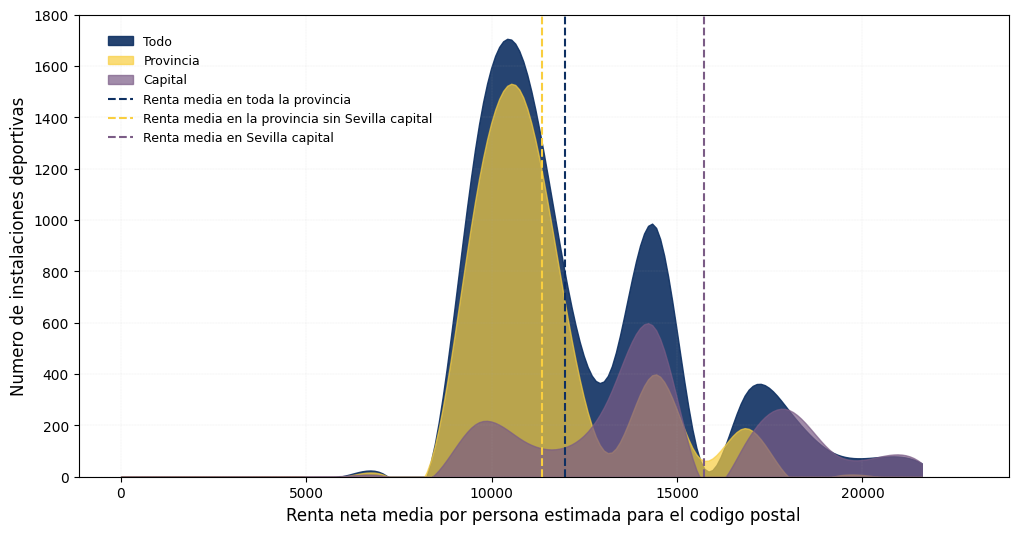

In [32]:
fig, ax = pl.subplots(1,1,figsize=(12, 6))
width = 1200
counts, bins, bars = ax.hist(data=provincia, x='renta_repartida', bins=np.arange(0, 24000, width),color='white', label=None)
counts2, bins2, bars2 = ax.hist(data=capital, x='renta_repartida', bins=np.arange(0, 24000, width),color='white', label=None)
counts3, bins3, bars3 = ax.hist(data=todo, x='renta_repartida', bins=np.arange(0, 24000, width),color='white', label=None)
xnew = np.linspace(0, bins[-2], num=200, endpoint=True)
f_cubic = interp1d(bins[:-1], counts[:], kind='cubic')
f_cubic2 = interp1d(bins2[:-1], counts2[:], kind='cubic')
f_cubic3 = interp1d(bins3[:-1], counts3[:], kind='cubic')
ax.fill_between(xnew, f_cubic3(xnew), alpha=0.9, color='#0e3062', label='Todo')
ax.fill_between(xnew, f_cubic(xnew), alpha=0.7, color='#F9CE3F', label='Provincia')
ax.fill_between(xnew, f_cubic2(xnew), alpha=0.7, color='#7B5C86', label='Capital')
ax.plot(y_tot,x,color='#0E3062', linestyle='--', label = "Renta media en toda la provincia")
ax.plot(y_pro,x,color='#F9CE3F', linestyle='--', label = "Renta media en la provincia sin Sevilla capital")
ax.plot(y_sev,x,color='#7B5C86',linestyle='--', label = "Renta media en Sevilla capital")
ax.set_ylim(0,1800)

ax.legend(fontsize=9,frameon=False,loc="upper left", bbox_to_anchor=(0.02,0.98))
ax.grid(linestyle='dotted',linewidth=.2, alpha=0.8)
ax.set_xlabel('Renta neta media por persona estimada para el codigo postal', fontsize=12,linespacing=10.2)
ax.set_ylabel('Numero de instalaciones deportivas', fontsize=12)
pl.show()

## 2.3 Distribución de instalaciones por nivel de renta en Sevilla capital por deporte

En esta sección realizamos un sencillo cálculo de dónde se sitúan respecto al nivel de renta aquellas instalaciones para la práctica del baloncest y los gimnasios, todo esto ya restringido al área de Sevilla capital.

Para ello filtramos los datos obtenidos tanto para el nombre del espacio deportivo como para el código postal de la capital.

In [34]:
datos_centros_basket = datos_centros[datos_centros['Espacio deportivo (texto libre)'].str.contains('BALONCESTO')==True]
datos_centros_gimnasio = datos_centros[datos_centros['Espacio deportivo (texto libre)'].str.contains('GIMNASIO')==True]
capital_basket = datos_centros_basket[datos_centros_basket['CPOS']<=41089]
capital_gimnasio = datos_centros_gimnasio[datos_centros_gimnasio['CPOS']<=41089]

## 2.3.1 Pistas de baloncesto

Para el caso del baloncesto, creamos un histograma similar al ya realizado utilizando la librería matplotlib y la interpolación.

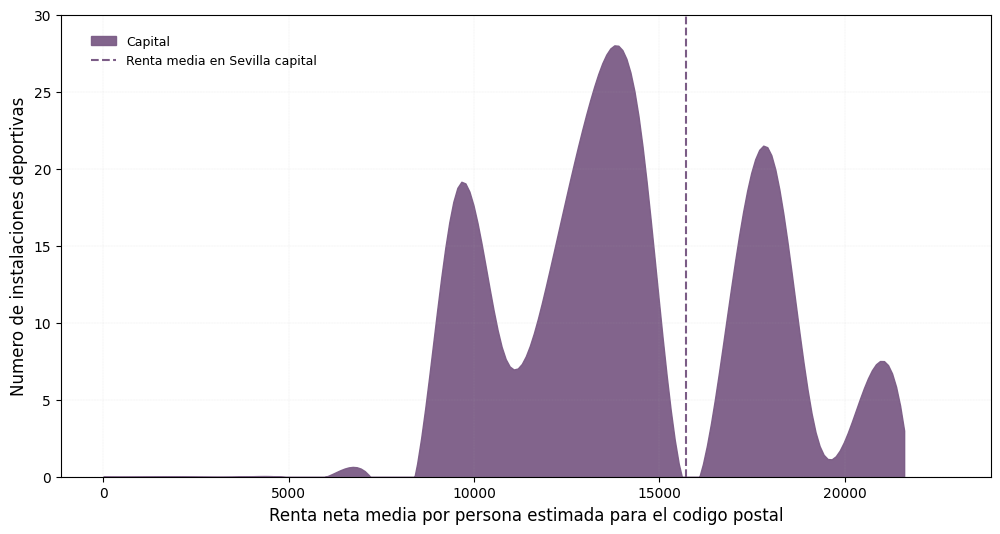

In [36]:
fig, ax = pl.subplots(1,1,figsize=(12, 6))
width = 1200
counts, bins, bars = ax.hist(data=capital_basket, x='renta_repartida', bins=np.arange(0, 24000, width),color='white', label=None)
xnew = np.linspace(0, bins[-2], num=200, endpoint=True)
f_cubic = interp1d(bins[:-1], counts[:], kind='cubic')
ax.fill_between(xnew, f_cubic(xnew), alpha=.95, color='#7B5C86', label='Capital')
ax.plot(y_sev,x,color='#7B5C86',linestyle='--', label = "Renta media en Sevilla capital")
ax.set_ylim(0,30)
ax.legend(fontsize=9,frameon=False,loc="upper left", bbox_to_anchor=(0.02,0.98))
ax.grid(linestyle='dotted',linewidth=.2, alpha=0.8)
ax.set_xlabel('Renta neta media por persona estimada para el codigo postal', fontsize=12,linespacing=4.2)
ax.set_ylabel('Numero de instalaciones deportivas', fontsize=12)
pl.show()

## 2.3.1 Gimnasios

Para el caso de los gimnasios, utilizamos la misma representación sobre las mismas escalas para poder comparar el resultado.

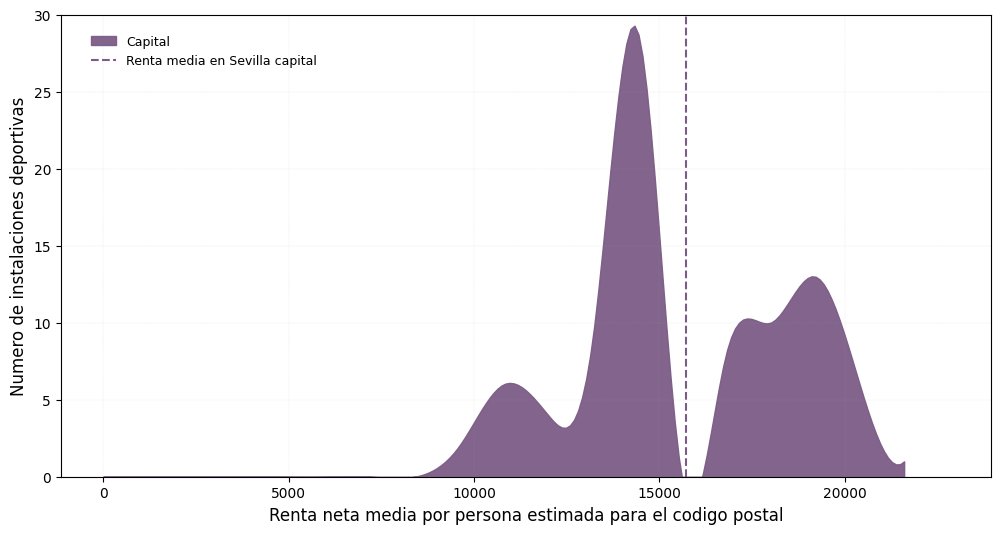

In [37]:
fig, ax = pl.subplots(1,1,figsize=(12, 6))
width = 1200
counts, bins, bars = ax.hist(data=capital_gimnasio, x='renta_repartida', bins=np.arange(0, 24000, width),color='white', label=None)
xnew = np.linspace(0, bins[-2], num=200, endpoint=True)
f_cubic = interp1d(bins[:-1], counts[:], kind='cubic')
ax.fill_between(xnew, f_cubic(xnew), alpha=0.95, color='#7B5C86', label='Capital')
ax.plot(y_sev,x,color='#7B5C86',linestyle='--', label = "Renta media en Sevilla capital")
ax.set_ylim(0,30)
ax.legend(fontsize=9,frameon=False,loc="upper left", bbox_to_anchor=(0.02,0.98))
ax.grid(linestyle='dotted',linewidth=.2, alpha=0.8)
ax.set_xlabel('Renta neta media por persona estimada para el codigo postal', fontsize=12,linespacing=4.2)
ax.set_ylabel('Numero de instalaciones deportivas', fontsize=12)
pl.show()